In [4]:

import re
import numpy as np
import pandas as pd
from rank_bm25 import BM25Okapi

print("All libraries imported successfully!")


All libraries imported successfully!


In [5]:

df = pd.read_csv("documents.csv")

print("Dataset loaded successfully!")
print("Number of documents:", len(df))
print("\nFirst five documents:")
display(df.head())


Dataset loaded successfully!
Number of documents: 15

First five documents:


,doc_id,title,content
0,1,AI Student Laptops,"Compare laptops with GPUs, powerful processors..."
1,2,Python for Machine Learning,Learn Python programming and machine learning ...
2,3,GPU Computing,GPUs accelerate deep learning through parallel...
3,4,College Study Tips,Improve academic performance through revision ...
4,5,Data Structures and Algorithms,"Learn arrays, trees, graphs, sorting, and sear..."


In [6]:

# Handle any empty cells
df = df.fillna("")

# Combine each document's title and content
df["text"] = df["title"] + " " + df["content"]

print("Combined title and content for each document.")
display(df[["doc_id", "title", "text"]].head())


Combined title and content for each document.


,doc_id,title,text
0,1,AI Student Laptops,"AI Student Laptops Compare laptops with GPUs, ..."
1,2,Python for Machine Learning,Python for Machine Learning Learn Python progr...
2,3,GPU Computing,GPU Computing GPUs accelerate deep learning th...
3,4,College Study Tips,College Study Tips Improve academic performanc...
4,5,Data Structures and Algorithms,"Data Structures and Algorithms Learn arrays, t..."


In [7]:

# Split text into lowercase words
def tokenize(text):
    return re.findall(r"\b\w+\b", str(text).lower())

# Tokenize all documents
documents = df["text"].tolist()
tokenized_documents = [tokenize(doc) for doc in documents]

# Display the first document and its tokens
print("Original document:")
print(documents[0])

print("\nTokenized document:")
print(tokenized_documents[0])


Original document:
AI Student Laptops Compare laptops with GPUs, powerful processors, and RAM for artificial intelligence students.

Tokenized document:
['ai', 'student', 'laptops', 'compare', 'laptops', 'with', 'gpus', 'powerful', 'processors', 'and', 'ram', 'for', 'artificial', 'intelligence', 'students']


In [8]:

# Build the BM25 index
bm25 = BM25Okapi(tokenized_documents)

# Try a sample search query
query = "AI laptops for students"
query_tokens = tokenize(query)

# Calculate a score for every document
scores = bm25.get_scores(query_tokens)

# Display the top 5 documents
top_indices = np.argsort(scores)[::-1][:5]

print("Search query:", query)
print("\nTop 5 retrieved documents:\n")

for rank, idx in enumerate(top_indices, start=1):
    print(f"Rank: {rank}")
    print("Document ID:", df.iloc[idx]["doc_id"])
    print("Title:", df.iloc[idx]["title"])
    print("BM25 Score:", round(float(scores[idx]), 4))
    print("-" * 40)


Search query: AI laptops for students

Top 5 retrieved documents:

Rank: 1
Document ID: 1
Title: AI Student Laptops
BM25 Score: 6.7485
----------------------------------------
Rank: 2
Document ID: 7
Title: Budget Laptops
BM25 Score: 2.3934
----------------------------------------
Rank: 3
Document ID: 15
Title: Exam Preparation
BM25 Score: 1.2614
----------------------------------------
Rank: 4
Document ID: 2
Title: Python for Machine Learning
BM25 Score: 1.2065
----------------------------------------
Rank: 5
Document ID: 12
Title: TF-IDF Similarity
BM25 Score: 0.0
----------------------------------------


In [9]:

from pathlib import Path

data_dir = Path("datasets/scifact")

print("Dataset folder exists:", data_dir.exists())
print("\nExtracted files:")

for path in data_dir.rglob("*"):
    if path.is_file():
        print(path)


Dataset folder exists: False

Extracted files:


In [10]:

from pathlib import Path
import os

print("Notebook working directory:")
print(os.getcwd())

print("\nFiles and folders in the working directory:")
for item in Path.cwd().iterdir():
    print(item.name)


Notebook working directory:
c:\Users\suhan\Documents\search_ranking_project

Files and folders in the working directory:
.venv
documents.csv
search_ranking.ipynb
venv


In [11]:

from pathlib import Path

downloads = Path.home() / "Downloads"

print("Searching Downloads for SciFact files...")

for path in downloads.rglob("*"):
    if "scifact" in path.name.lower():
        print(path)


Searching Downloads for SciFact files...
C:\Users\suhan\Downloads\scifact (1)
C:\Users\suhan\Downloads\scifact (1).zip
C:\Users\suhan\Downloads\scifact.zip
C:\Users\suhan\Downloads\scifact (1)\scifact


In [12]:

from pathlib import Path

dataset_path = Path.home() / "Downloads" / "scifact (1)" / "scifact"

print("Dataset path exists:", dataset_path.exists())
print("\nDataset files:")

for path in dataset_path.rglob("*"):
    if path.is_file():
        print(path)


Dataset path exists: True

Dataset files:
C:\Users\suhan\Downloads\scifact (1)\scifact\corpus.jsonl
C:\Users\suhan\Downloads\scifact (1)\scifact\queries.jsonl
C:\Users\suhan\Downloads\scifact (1)\scifact\qrels\test.tsv
C:\Users\suhan\Downloads\scifact (1)\scifact\qrels\train.tsv


In [13]:

import json
import pandas as pd
from pathlib import Path

dataset_path = Path.home() / "Downloads" / "scifact (1)" / "scifact"

# Find the main dataset files
for path in dataset_path.rglob("*"):
    if path.is_file():
        print(path.name, "->", path)


corpus.jsonl -> C:\Users\suhan\Downloads\scifact (1)\scifact\corpus.jsonl
queries.jsonl -> C:\Users\suhan\Downloads\scifact (1)\scifact\queries.jsonl
test.tsv -> C:\Users\suhan\Downloads\scifact (1)\scifact\qrels\test.tsv
train.tsv -> C:\Users\suhan\Downloads\scifact (1)\scifact\qrels\train.tsv


In [14]:

import json
import pandas as pd
from pathlib import Path

# Location of the downloaded SciFact dataset
dataset_path = (
    Path.home() / "Downloads" / "scifact (1)" / "scifact"
)

# Load scientific documents
corpus_records = []

with open(dataset_path / "corpus.jsonl", "r", encoding="utf-8") as file:
    for line in file:
        corpus_records.append(json.loads(line))

corpus_df = pd.DataFrame(corpus_records)

# Load search queries
query_records = []

with open(dataset_path / "queries.jsonl", "r", encoding="utf-8") as file:
    for line in file:
        query_records.append(json.loads(line))

queries_df = pd.DataFrame(query_records)

# Load training and test relevance judgments
train_qrels = pd.read_csv(
    dataset_path / "qrels" / "train.tsv",
    sep="\t"
)

test_qrels = pd.read_csv(
    dataset_path / "qrels" / "test.tsv",
    sep="\t"
)

print("SciFact dataset loaded successfully!")
print("Number of documents:", len(corpus_df))
print("Number of queries:", len(queries_df))
print("Training relevance judgments:", len(train_qrels))
print("Test relevance judgments:", len(test_qrels))

print("\nDocument columns:")
print(corpus_df.columns.tolist())

print("\nFirst five documents:")
display(corpus_df.head())

print("\nFirst five queries:")
display(queries_df.head())

print("\nTraining relevance labels:")
display(train_qrels.head())


SciFact dataset loaded successfully!
Number of documents: 5183
Number of queries: 1109
Training relevance judgments: 919
Test relevance judgments: 339

Document columns:
['_id', 'title', 'text', 'metadata']

First five documents:


,_id,title,text,metadata
0,4983,Microstructural development of human newborn c...,Alterations of the architecture of cerebral wh...,{}
1,5836,Induction of myelodysplasia by myeloid-derived...,Myelodysplastic syndromes (MDS) are age-depend...,{}
2,7912,"BC1 RNA, the transcript from a master gene for...",ID elements are short interspersed elements (S...,{}
3,18670,The DNA Methylome of Human Peripheral Blood Mo...,DNA methylation plays an important role in bio...,{}
4,19238,The human myelin basic protein gene is include...,Two human Golli (for gene expressed in the oli...,{}



First five queries:


,_id,text,metadata
0,0,0-dimensional biomaterials lack inductive prop...,{}
1,2,1 in 5 million in UK have abnormal PrP positiv...,"{'13734012': [{'sentences': [4], 'label': 'CON..."
2,4,1-1% of colorectal cancer patients are diagnos...,{}
3,6,10% of sudden infant death syndrome (SIDS) dea...,{}
4,9,32% of liver transplantation programs required...,"{'44265107': [{'sentences': [15], 'label': 'SU..."



Training relevance labels:


,query-id,corpus-id,score
0,0,31715818,1
1,2,13734012,1
2,4,22942787,1
3,6,2613775,1
4,9,44265107,1


In [15]:

import re
import numpy as np
from rank_bm25 import BM25Okapi

# Combine each scientific document's title and text
corpus_df["title"] = corpus_df["title"].fillna("")
corpus_df["text"] = corpus_df["text"].fillna("")

corpus_df["full_text"] = (
    corpus_df["title"] + " " + corpus_df["text"]
)

# Convert text into lowercase word tokens
def tokenize(text):
    return re.findall(r"\b\w+\b", str(text).lower())

# Tokenize the entire scientific corpus
tokenized_corpus = [
    tokenize(document)
    for document in corpus_df["full_text"]
]

print("Document preparation complete!")
print("Documents prepared:", len(tokenized_corpus))
print("\nExample document:")
print(corpus_df.iloc[0]["title"])
print("\nFirst 20 tokens:")
print(tokenized_corpus[0][:20])


Document preparation complete!
Documents prepared: 5183

Example document:
Microstructural development of human newborn cerebral white matter assessed in vivo by diffusion tensor magnetic resonance imaging.

First 20 tokens:
['microstructural', 'development', 'of', 'human', 'newborn', 'cerebral', 'white', 'matter', 'assessed', 'in', 'vivo', 'by', 'diffusion', 'tensor', 'magnetic', 'resonance', 'imaging', 'alterations', 'of', 'the']


In [16]:

print("Building BM25 index...")

bm25 = BM25Okapi(tokenized_corpus)

print("BM25 index built successfully!")


Building BM25 index...
BM25 index built successfully!


In [17]:

# Select the first query from the SciFact query collection
sample_query = str(queries_df.iloc[0]["text"])
sample_query_id = str(queries_df.iloc[0]["_id"])

query_tokens = tokenize(sample_query)

# Retrieve BM25 scores for every document
scores = bm25.get_scores(query_tokens)

# Select the five highest-scoring documents
top_indices = np.argsort(scores)[::-1][:5]

print("Query ID:", sample_query_id)
print("Search query:", sample_query)
print("\nTop 5 retrieved documents:\n")

for rank, idx in enumerate(top_indices, start=1):
    print(f"Rank: {rank}")
    print("Document ID:", corpus_df.iloc[idx]["_id"])
    print("Title:", corpus_df.iloc[idx]["title"])
    print("BM25 score:", round(float(scores[idx]), 4))
    print("-" * 60)


Query ID: 0
Search query: 0-dimensional biomaterials lack inductive properties.

Top 5 retrieved documents:

Rank: 1
Document ID: 10608397
Title: High-performance neuroprosthetic control by an individual with tetraplegia.
BM25 score: 10.1737
------------------------------------------------------------
Rank: 2
Document ID: 40212412
Title: Periosteal bone formation--a neglected determinant of bone strength.
BM25 score: 9.557
------------------------------------------------------------
Rank: 3
Document ID: 825728
Title: Metastatic colonization requires the repression of the epithelial-mesenchymal transition inducer Prrx1.
BM25 score: 9.318
------------------------------------------------------------
Rank: 4
Document ID: 4435369
Title: Extracellular vesicles for drug delivery.
BM25 score: 9.2261
------------------------------------------------------------
Rank: 5
Document ID: 28138927
Title: Potent, Selective, and Orally Bioavailable Inhibitors of VPS34 Provide Chemical Tools to Modulate A

In [18]:

# Make sure query and document IDs use the same type
train_qrels["query-id"] = train_qrels["query-id"].astype(str)
train_qrels["corpus-id"] = train_qrels["corpus-id"].astype(str)

test_qrels["query-id"] = test_qrels["query-id"].astype(str)
test_qrels["corpus-id"] = test_qrels["corpus-id"].astype(str)

# Check whether this query appears in the training or test labels
print("Query ID:", sample_query_id)

print("\nTraining relevance judgments:")
display(
    train_qrels[
        train_qrels["query-id"] == sample_query_id
    ]
)

print("\nTest relevance judgments:")
display(
    test_qrels[
        test_qrels["query-id"] == sample_query_id
    ]
)


Query ID: 0

Training relevance judgments:


,query-id,corpus-id,score
0,0,31715818,1



Test relevance judgments:


,query-id,corpus-id,score


In [19]:

from collections import defaultdict
import math

# Group test relevance judgments by query
relevance_by_query = defaultdict(dict)

for _, row in test_qrels.iterrows():
    relevance_by_query[str(row["query-id"])][
        str(row["corpus-id"])
    ] = int(row["score"])

# Map query IDs to their query text
query_text_by_id = {
    str(row["_id"]): str(row["text"])
    for _, row in queries_df.iterrows()
}

def dcg_at_k(relevances, k=10):
    return sum(
        (2**rel - 1) / math.log2(position + 1)
        for position, rel in enumerate(relevances[:k], start=1)
    )

def evaluate_bm25(k=10):
    reciprocal_ranks = []
    ndcg_scores = []

    for query_id, judged_docs in relevance_by_query.items():
        query_text = query_text_by_id.get(query_id)

        if query_text is None:
            continue

        scores = bm25.get_scores(tokenize(query_text))
        top_indices = np.argsort(scores)[::-1][:k]

        ranked_doc_ids = [
            str(corpus_df.iloc[idx]["_id"])
            for idx in top_indices
        ]

        ranked_relevances = [
            judged_docs.get(doc_id, 0)
            for doc_id in ranked_doc_ids
        ]

        # Reciprocal rank of the first relevant result
        reciprocal_rank = 0.0
        for rank, rel in enumerate(ranked_relevances, start=1):
            if rel > 0:
                reciprocal_rank = 1 / rank
                break

        reciprocal_ranks.append(reciprocal_rank)

        # NDCG uses graded relevance scores
        dcg = dcg_at_k(ranked_relevances, k)

        ideal_relevances = sorted(
            judged_docs.values(), reverse=True
        )[:k]
        ideal_dcg = dcg_at_k(ideal_relevances, k)

        ndcg_scores.append(
            dcg / ideal_dcg if ideal_dcg > 0 else 0.0
        )

    return {
        "Evaluated queries": len(reciprocal_ranks),
        "MRR@10": round(float(np.mean(reciprocal_ranks)), 4),
        "NDCG@10": round(float(np.mean(ndcg_scores)), 4),
    }

baseline_metrics = evaluate_bm25()
print("BM25 baseline evaluation:")
print(baseline_metrics)


BM25 baseline evaluation:
{'Evaluated queries': 300, 'MRR@10': 0.6186, 'NDCG@10': 0.6519}


In [20]:

# Convert IDs to strings for consistent matching
corpus_df["_id"] = corpus_df["_id"].astype(str)
queries_df["_id"] = queries_df["_id"].astype(str)

# Build lookup tables
query_text_by_id = {
    str(row["_id"]): str(row["text"])
    for _, row in queries_df.iterrows()
}

doc_index_by_id = {
    str(doc_id): idx
    for idx, doc_id in enumerate(corpus_df["_id"])
}

# Group training relevance judgments by query
train_relevant = defaultdict(set)

for _, row in train_qrels.iterrows():
    if int(row["score"]) > 0:
        train_relevant[str(row["query-id"])].add(
            str(row["corpus-id"])
        )

print("Queries with positive training labels:", len(train_relevant))
print("Training relevance pairs:", sum(
    len(doc_ids) for doc_ids in train_relevant.values()
))


Queries with positive training labels: 809
Training relevance pairs: 919


In [21]:

def extract_features(query, idx, bm25_score):
    query_tokens = tokenize(query)
    query_words = set(query_tokens)
    doc_words = set(tokenized_corpus[idx])

    overlap = len(query_words & doc_words)
    coverage = overlap / max(len(query_words), 1)
    doc_length = len(tokenized_corpus[idx])

    title_words = set(tokenize(corpus_df.iloc[idx]["title"]))
    title_overlap = len(query_words & title_words)

    return [
        bm25_score,
        overlap,
        coverage,
        doc_length,
        title_overlap
    ]

X_train_rows = []
y_train_rows = []

for query_id, relevant_ids in train_relevant.items():
    query = query_text_by_id.get(query_id)

    if query is None:
        continue

    scores = bm25.get_scores(tokenize(query))
    candidate_indices = np.argsort(scores)[::-1][:50]

    # Include known relevant documents even if BM25
    # did not retrieve them in the top 50.
    relevant_indices = [
        doc_index_by_id[doc_id]
        for doc_id in relevant_ids
        if doc_id in doc_index_by_id
    ]

    candidate_indices = sorted(
        set(candidate_indices.tolist() + relevant_indices)
    )

    for idx in candidate_indices:
        doc_id = str(corpus_df.iloc[idx]["_id"])

        X_train_rows.append(
            extract_features(query, idx, scores[idx])
        )
        y_train_rows.append(int(doc_id in relevant_ids))

X_train = np.asarray(X_train_rows, dtype=float)
y_train = np.asarray(y_train_rows, dtype=float)

print("Training matrix shape:", X_train.shape)
print("Relevant examples:", int(y_train.sum()))
print("Non-relevant/unjudged examples:", int(len(y_train) - y_train.sum()))


Training matrix shape: (40573, 5)
Relevant examples: 919
Non-relevant/unjudged examples: 39654


In [22]:

# Normalize features using training data only
feature_mean = X_train.mean(axis=0)
feature_std = X_train.std(axis=0)
feature_std[feature_std == 0] = 1

X_scaled = (X_train - feature_mean) / feature_std
X_bias = np.column_stack([np.ones(len(X_scaled)), X_scaled])

# Logistic regression trained with gradient descent
weights = np.zeros(X_bias.shape[1])
learning_rate = 0.05

for epoch in range(1500):
    z = np.clip(X_bias @ weights, -30, 30)
    probabilities = 1 / (1 + np.exp(-z))

    gradient = X_bias.T @ (probabilities - y_train) / len(y_train)
    weights -= learning_rate * gradient

print("Reranking model trained successfully!")
print("Learned feature weights:", weights)


Reranking model trained successfully!
Learned feature weights: [-3.73847714  0.57901708 -0.27018316  0.46150502 -0.00692418  0.16385358]


In [23]:

def rerank_search(query, top_k=10, candidate_k=50):
    # Stage 1: Retrieve candidates using BM25
    scores = bm25.get_scores(tokenize(query))
    candidate_indices = np.argsort(scores)[::-1][:candidate_k]

    # Stage 2: Extract features and predict relevance
    features = np.array([
        extract_features(query, idx, scores[idx])
        for idx in candidate_indices
    ], dtype=float)

    scaled = (features - feature_mean) / feature_std
    bias = np.column_stack([np.ones(len(scaled)), scaled])

    logits = np.clip(bias @ weights, -30, 30)
    probabilities = 1 / (1 + np.exp(-logits))

    # Sort candidates by predicted relevance
    order = np.argsort(probabilities)[::-1][:top_k]

    return [
        {
            "doc_id": str(corpus_df.iloc[candidate_indices[i]]["_id"]),
            "title": corpus_df.iloc[candidate_indices[i]]["title"],
            "bm25_score": float(scores[candidate_indices[i]]),
            "relevance_score": float(probabilities[i])
        }
        for i in order
    ]


def evaluate_reranker(k=10):
    reciprocal_ranks = []
    ndcg_scores = []

    for query_id, judged_docs in relevance_by_query.items():
        query_text = query_text_by_id.get(query_id)
        if query_text is None:
            continue

        results = rerank_search(query_text, top_k=k)
        ranked_relevances = [
            judged_docs.get(result["doc_id"], 0)
            for result in results
        ]

        # MRR@k
        rr = 0.0
        for rank, rel in enumerate(ranked_relevances, start=1):
            if rel > 0:
                rr = 1 / rank
                break
        reciprocal_ranks.append(rr)

        # NDCG@k
        dcg = dcg_at_k(ranked_relevances, k)
        ideal = dcg_at_k(sorted(judged_docs.values(), reverse=True), k)
        ndcg_scores.append(dcg / ideal if ideal > 0 else 0.0)

    return {
        "Evaluated queries": len(reciprocal_ranks),
        "MRR@10": round(float(np.mean(reciprocal_ranks)), 4),
        "NDCG@10": round(float(np.mean(ndcg_scores)), 4)
    }


reranker_metrics = evaluate_reranker()

print("BM25 baseline:", baseline_metrics)
print("ML reranker:", reranker_metrics)


BM25 baseline: {'Evaluated queries': 300, 'MRR@10': 0.6186, 'NDCG@10': 0.6519}
ML reranker: {'Evaluated queries': 300, 'MRR@10': 0.6019, 'NDCG@10': 0.6322}


In [24]:

# Reuse the existing training data and feature scaling
positive_count = int(y_train.sum())
negative_count = len(y_train) - positive_count

# Moderate positive-class weighting
positive_weight = np.sqrt(negative_count / positive_count)

sample_weights = np.where(
    y_train == 1,
    positive_weight,
    1.0
)

print("Positive examples:", positive_count)
print("Negative examples:", negative_count)
print("Positive class weight:", round(positive_weight, 3))

# Recreate the normalized training matrix
X_scaled = (X_train - feature_mean) / feature_std
X_bias = np.column_stack([np.ones(len(X_scaled)), X_scaled])

# Train a fresh model
weighted_weights = np.zeros(X_bias.shape[1])
learning_rate = 0.05

for epoch in range(1500):
    z = np.clip(X_bias @ weighted_weights, -30, 30)
    probabilities = 1 / (1 + np.exp(-z))

    errors = (probabilities - y_train) * sample_weights
    gradient = X_bias.T @ errors / sample_weights.sum()

    weighted_weights -= learning_rate * gradient

print("\nClass-weighted model trained!")
print("Weights:", weighted_weights)


Positive examples: 919
Negative examples: 39654
Positive class weight: 6.569

Class-weighted model trained!
Weights: [-2.47522189  0.98945133 -0.86018386  0.67601244  0.00811345  0.22038691]


In [25]:

# Save the original model weights
original_weights = weights.copy()

# Evaluate the class-weighted model
weights = weighted_weights.copy()
weighted_metrics = evaluate_reranker()

print("BM25 baseline:", baseline_metrics)
print("Original ML reranker:", reranker_metrics)
print("Class-weighted reranker:", weighted_metrics)

# Keep the class-weighted model only for experimentation.
# Restore the original model until we decide which to retain.
weights = original_weights


BM25 baseline: {'Evaluated queries': 300, 'MRR@10': 0.6186, 'NDCG@10': 0.6519}
Original ML reranker: {'Evaluated queries': 300, 'MRR@10': 0.6019, 'NDCG@10': 0.6322}
Class-weighted reranker: {'Evaluated queries': 300, 'MRR@10': 0.6118, 'NDCG@10': 0.6424}


In [26]:
# Split training queries into training and validation groups
import numpy as np

all_train_query_ids = sorted(
    train_qrels["query-id"].astype(str).unique()
)

rng = np.random.default_rng(42)
shuffled_ids = rng.permutation(all_train_query_ids)

split_index = int(0.8 * len(shuffled_ids))

training_query_ids = set(shuffled_ids[:split_index])
validation_query_ids = set(shuffled_ids[split_index:])

train_qrels_split = train_qrels[
    train_qrels["query-id"].astype(str).isin(training_query_ids)
].copy()

validation_qrels = train_qrels[
    train_qrels["query-id"].astype(str).isin(validation_query_ids)
].copy()

print("Training queries:", len(training_query_ids))
print("Validation queries:", len(validation_query_ids))
print("Training relevance judgments:", len(train_qrels_split))
print("Validation relevance judgments:", len(validation_qrels))

Training queries: 647
Validation queries: 162
Training relevance judgments: 742
Validation relevance judgments: 177


In [27]:

from collections import defaultdict
import numpy as np

# Relevant documents for training queries only
train_relevant_split = defaultdict(set)

for _, row in train_qrels_split.iterrows():
    if int(row["score"]) > 0:
        train_relevant_split[str(row["query-id"])].add(
            str(row["corpus-id"])
        )

print("Training queries with relevant documents:",
      len(train_relevant_split))

print("Relevant query-document pairs:",
      sum(len(docs) for docs in train_relevant_split.values()))


Training queries with relevant documents: 647
Relevant query-document pairs: 742


In [28]:

X_train_split = []
y_train_split = []

for query_id, relevant_ids in train_relevant_split.items():

    # Get the query text
    query = query_text_by_id.get(query_id)

    if query is None:
        continue

    # Retrieve the top 50 candidate documents using BM25
    query_tokens = tokenize(query)
    scores = bm25.get_scores(query_tokens)
    candidate_indices = np.argsort(scores)[::-1][:50]

    # Include all relevant documents, even if BM25
    # did not place them in the top 50
    relevant_indices = [
        doc_index_by_id[doc_id]
        for doc_id in relevant_ids
        if doc_id in doc_index_by_id
    ]

    candidate_indices = set(candidate_indices.tolist())
    candidate_indices.update(relevant_indices)

    # Extract features and labels
    for idx in candidate_indices:
        score = float(scores[idx])

        features = extract_features(query, idx, score)
        label = int(
            str(corpus_df.iloc[idx]["_id"]) in relevant_ids
        )

        X_train_split.append(features)
        y_train_split.append(label)

X_train_split = np.asarray(X_train_split, dtype=float)
y_train_split = np.asarray(y_train_split, dtype=int)

print("Training feature matrix:", X_train_split.shape)
print("Positive examples:", int(y_train_split.sum()))
print("Negative examples:", int(len(y_train_split) - y_train_split.sum()))


Training feature matrix: (32446, 5)
Positive examples: 742
Negative examples: 31704


In [29]:

# Normalize training features
feature_mean_split = X_train_split.mean(axis=0)
feature_std_split = X_train_split.std(axis=0)
feature_std_split[feature_std_split == 0] = 1

X_scaled_split = (
    X_train_split - feature_mean_split
) / feature_std_split

# Add bias column
X_bias_split = np.column_stack([
    np.ones(len(X_scaled_split)),
    X_scaled_split
])

# Calculate class weights
positive_count = int(y_train_split.sum())
negative_count = len(y_train_split) - positive_count

positive_weight_split = np.sqrt(
    negative_count / positive_count
)

sample_weights_split = np.where(
    y_train_split == 1,
    positive_weight_split,
    1.0
)

# Train logistic regression from scratch
weights_split = np.zeros(X_bias_split.shape[1])
learning_rate = 0.05

for epoch in range(1500):
    z = np.clip(X_bias_split @ weights_split, -30, 30)
    probabilities = 1 / (1 + np.exp(-z))

    errors = (
        probabilities - y_train_split
    ) * sample_weights_split

    gradient = (
        X_bias_split.T @ errors
    ) / sample_weights_split.sum()

    weights_split -= learning_rate * gradient

print("Model training completed!")
print("Training examples:", len(y_train_split))
print("Positive class weight:", round(positive_weight_split, 3))
print("Learned weights:", weights_split)


Model training completed!
Training examples: 32446
Positive class weight: 6.537
Learned weights: [-2.48884796  0.99728165 -0.86626915  0.68845825  0.01358284  0.2390256 ]


In [30]:

def rerank_search_split(query, top_k=10, candidate_k=50):
    query_tokens = tokenize(query)
    scores = bm25.get_scores(query_tokens)

    candidate_indices = np.argsort(scores)[::-1][:candidate_k]

    features = np.array([
        extract_features(query, idx, float(scores[idx]))
        for idx in candidate_indices
    ], dtype=float)

    scaled_features = (
        features - feature_mean_split
    ) / feature_std_split

    bias_features = np.column_stack([
        np.ones(len(scaled_features)),
        scaled_features
    ])

    z = np.clip(bias_features @ weights_split, -30, 30)
    probabilities = 1 / (1 + np.exp(-z))

    order = np.argsort(probabilities)[::-1][:top_k]

    return [
        (int(candidate_indices[i]), float(probabilities[i]))
        for i in order
    ]


# Evaluate using validation relevance judgments only
validation_relevance = defaultdict(dict)

for _, row in validation_qrels.iterrows():
    validation_relevance[str(row["query-id"])][
        str(row["corpus-id"])
    ] = int(row["score"])


def evaluate_validation(use_reranker=True, k=10):
    reciprocal_ranks = []
    ndcg_scores = []

    for query_id, relevance in validation_relevance.items():
        query = query_text_by_id.get(query_id)

        if query is None:
            continue

        if use_reranker:
            results = rerank_search_split(query, top_k=k)
            ranked_indices = [idx for idx, _ in results]
        else:
            scores = bm25.get_scores(tokenize(query))
            ranked_indices = np.argsort(scores)[::-1][:k]

        ranked_relevances = [
            relevance.get(str(corpus_df.iloc[idx]["_id"]), 0)
            for idx in ranked_indices
        ]

        relevant_ranks = [
            rank for rank, rel in enumerate(ranked_relevances, start=1)
            if rel > 0
        ]

        reciprocal_ranks.append(
            1 / relevant_ranks[0] if relevant_ranks else 0
        )

        dcg = sum(
            (2**rel - 1) / np.log2(rank + 1)
            for rank, rel in enumerate(ranked_relevances, start=1)
        )

        ideal_relevances = sorted(
            relevance.values(), reverse=True
        )[:k]

        ideal_dcg = sum(
            (2**rel - 1) / np.log2(rank + 1)
            for rank, rel in enumerate(ideal_relevances, start=1)
        )

        ndcg_scores.append(dcg / ideal_dcg if ideal_dcg else 0)

    return {
        "Evaluated queries": len(reciprocal_ranks),
        "MRR@10": round(float(np.mean(reciprocal_ranks)), 4),
        "NDCG@10": round(float(np.mean(ndcg_scores)), 4)
    }


validation_bm25_metrics = evaluate_validation(use_reranker=False)
validation_ml_metrics = evaluate_validation(use_reranker=True)

print("BM25 validation:", validation_bm25_metrics)
print("ML reranker validation:", validation_ml_metrics)


BM25 validation: {'Evaluated queries': 162, 'MRR@10': 0.5879, 'NDCG@10': 0.619}
ML reranker validation: {'Evaluated queries': 162, 'MRR@10': 0.5831, 'NDCG@10': 0.6125}


In [31]:

def search_documents(query, top_k=10):
    query_tokens = tokenize(query)

    if not query_tokens:
        print("Please enter a valid search query.")
        return pd.DataFrame()

    scores = bm25.get_scores(query_tokens)
    top_indices = np.argsort(scores)[::-1][:top_k]

    results = []

    for rank, idx in enumerate(top_indices, start=1):
        doc = corpus_df.iloc[idx]

        results.append({
            "Rank": rank,
            "Document ID": str(doc["_id"]),
            "Title": doc["title"],
            "BM25 Score": round(float(scores[idx]), 4),
            "Text Preview": str(doc["text"])[:250] + "..."
        })

    return pd.DataFrame(results)


# Try a sample search
search_results = search_documents(
    "What evidence supports the effectiveness of biomaterials?",
    top_k=10
)

display(search_results)


,Rank,Document ID,Title,BM25 Score,Text Preview
0,1,15670968,Thresholds for the cost–effectiveness of inter...,22.3291,Many countries use the cost-effectiveness thre...
1,2,8447873,Systematic review of controlled clinical trial...,19.2411,BACKGROUND Organophosphorus pesticide (OP) sel...
2,3,11748341,Evidence-based interventions for improvement o...,18.9559,"Maternal undernutrition contributes to 800,000..."
3,4,22446093,What is the best way to help caregivers in can...,18.6275,Informal carers in cancer and palliative care ...
4,5,26016929,Effectiveness of screening older people for im...,18.1527,OBJECTIVE To assess whether population screeni...
5,6,7074001,Evidence into practice. Application of psychol...,17.5489,Psychiatrists have long recognised that routin...
6,7,7613033,Aspirin in the chemoprevention of colorectal n...,17.3293,Considerable evidence supports the effectivene...
7,8,32697244,The Neurovascular Unit Coming of Age: A Journe...,17.0064,"The concept of the neurovascular unit (NVU), f..."
8,9,8042158,Systematic reviews from astronomy to zoology: ...,16.8274,Systematic literature reviews are widely used ...
9,10,70439309,Cost-effectiveness in health and medicine,16.7296,1. Cost-Effectiveness Analysis as a Guide to R...


In [32]:

import ipywidgets as widgets
from IPython.display import display, clear_output

query_box = widgets.Text(
    value="",
    placeholder="Enter your search query...",
    description="Search:",
    layout=widgets.Layout(width="75%")
)

search_button = widgets.Button(
    description="Search",
    button_style="primary",
    icon="search"
)

output_area = widgets.Output()

def on_search_clicked(button):
    with output_area:
        clear_output(wait=True)

        query = query_box.value.strip()

        if not query:
            print("Please enter a search query.")
            return

        results = search_documents(query, top_k=10)
        display(results)

search_button.on_click(on_search_clicked)

display(
    widgets.VBox([
        widgets.HBox([query_box, search_button]),
        output_area
    ])
)


In [33]:
%pip install ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [ ]:

import ipywidgets as widgets
from IPython.display import display, clear_output

query_box = widgets.Text(
    value="",
    placeholder="Enter your search query...",
    description="Search:",
    layout=widgets.Layout(width="75%")
)

search_button = widgets.Button(
    description="Search",
    button_style="primary",
    icon="search"
)

output_area = widgets.Output()

def on_search_clicked(button):
    with output_area:
        clear_output(wait=True)

        query = query_box.value.strip()

        if not query:
            print("Please enter a search query.")
            return

        results = search_documents(query, top_k=10)
        display(results)

search_button.on_click(on_search_clicked)

display(
    widgets.VBox([
        widgets.HBox([query_box, search_button]),
        output_area
    ])
)


In [35]:
print("ipywidgets available:", "widgets" in globals())
print("Search box created:", "query_box" in globals())
print("Search button created:", "search_button" in globals())
print("Output widget created:", "output_area" in globals())

ipywidgets available: True
Search box created: True
Search button created: True
Output widget created: True


In [36]:

from IPython.display import display, Markdown

query = input("Enter your search query: ")

results = search_documents(query, top_k=10)

if not results.empty:
    display(results)


,Rank,Document ID,Title,BM25 Score,Text Preview
0,1,12789595,Computer assisted learning in undergraduate me...,17.0864,It is becoming “a truth universally acknowledg...
1,2,14652521,A framework for improving microRNA prediction ...,16.0590,The prediction of novel pre-microRNA (miRNA) f...
2,3,30500829,Correlation and variable importance in random ...,15.6149,This paper is about variable selection with th...
3,4,9547722,Cancer survivors in the United States: prevale...,13.2139,BACKGROUND Cancer survivors represent a growin...
4,5,11256632,Protein-Protein Interaction Inhibition (2P2I)-...,13.2131,Protein-protein interactions (PPIs) represent ...
5,6,8327914,A Protein Inventory of Human Ribosome Biogenes...,13.1797,The assembly of ribosomal subunits in eukaryot...
6,7,3202143,Insulin Signaling and Dietary Restriction Diff...,12.4196,"Of all the age-related declines, memory loss i..."
7,8,46355579,Rapid clearance of human papillomavirus and im...,12.3422,Health professionals and the public need to un...
8,9,32084655,Time from finding abnormality on mass-screenin...,12.1957,Mass-screening for lung cancer is rather a uni...
9,10,1542437,Robustness of Random Forest-based gene selecti...,11.8827,Gene selection is an important part of microar...


In [37]:

required_variables = [
    "corpus_df",
    "queries_df",
    "train_qrels_split",
    "validation_qrels",
    "bm25",
    "X_train_split",
    "y_train_split",
    "feature_mean_split",
    "feature_std_split",
    "weights_split",
    "search_documents"
]

for name in required_variables:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")


corpus_df: Available
queries_df: Available
train_qrels_split: Available
validation_qrels: Available
bm25: Available
X_train_split: Available
y_train_split: Available
feature_mean_split: Available
feature_std_split: Available
weights_split: Available
search_documents: Available


In [38]:
query = input("Enter your search query: ")

results = search_documents(query, top_k=10)

if not results.empty:
    display(results)

,Rank,Document ID,Title,BM25 Score,Text Preview
0,1,12789595,Computer assisted learning in undergraduate me...,17.0864,It is becoming “a truth universally acknowledg...
1,2,14652521,A framework for improving microRNA prediction ...,16.0590,The prediction of novel pre-microRNA (miRNA) f...
2,3,30500829,Correlation and variable importance in random ...,15.6149,This paper is about variable selection with th...
3,4,9547722,Cancer survivors in the United States: prevale...,13.2139,BACKGROUND Cancer survivors represent a growin...
4,5,11256632,Protein-Protein Interaction Inhibition (2P2I)-...,13.2131,Protein-protein interactions (PPIs) represent ...
5,6,8327914,A Protein Inventory of Human Ribosome Biogenes...,13.1797,The assembly of ribosomal subunits in eukaryot...
6,7,3202143,Insulin Signaling and Dietary Restriction Diff...,12.4196,"Of all the age-related declines, memory loss i..."
7,8,46355579,Rapid clearance of human papillomavirus and im...,12.3422,Health professionals and the public need to un...
8,9,32084655,Time from finding abnormality on mass-screenin...,12.1957,Mass-screening for lung cancer is rather a uni...
9,10,1542437,Robustness of Random Forest-based gene selecti...,11.8827,Gene selection is an important part of microar...


In [39]:

import importlib.util

libraries = {
    "scikit-learn": "sklearn",
    "XGBoost": "xgboost",
    "NumPy": "numpy",
    "pandas": "pandas"
}

for name, module in libraries.items():
    try:
        available = importlib.util.find_spec(module) is not None
        print(f"{name}: {'Installed' if available else 'Not installed'}")
    except (ImportError, ValueError):
        print(f"{name}: Not available")


scikit-learn: Installed
XGBoost: Not installed
NumPy: Installed
pandas: Installed


In [40]:

try:
    from sklearn.svm import LinearSVC
    print("Linear SVM: Working")
except Exception as e:
    print("Linear SVM: Failed")
    print(type(e).__name__, e)

try:
    from sklearn.ensemble import RandomForestClassifier
    print("Random Forest: Working")
except Exception as e:
    print("Random Forest: Failed")
    print(type(e).__name__, e)


Linear SVM: Working
Random Forest: Working


In [41]:

from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import time

# Calculate class weights because relevant documents are much fewer
# than irrelevant documents
classes = np.unique(y_train_split)
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_split
)
class_weight_dict = dict(zip(classes, class_weights))

print("Training Linear SVM...")
start = time.time()

svm_model = LinearSVC(
    class_weight="balanced",
    random_state=42,
    max_iter=5000
)
svm_model.fit(X_train_split, y_train_split)

print(f"Linear SVM trained in {time.time() - start:.2f} seconds.")

print("\nTraining Random Forest...")
start = time.time()

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_split, y_train_split)

print(f"Random Forest trained in {time.time() - start:.2f} seconds.")
print("\nBoth models are ready!")


Training Linear SVM...
Linear SVM trained in 0.08 seconds.

Training Random Forest...
Random Forest trained in 0.51 seconds.

Both models are ready!


In [42]:

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import numpy as np
import pandas as pd

# Build the validation relevance mapping
from collections import defaultdict

validation_relevance = defaultdict(set)

for _, row in validation_qrels.iterrows():
    if int(row["score"]) > 0:
        validation_relevance[str(row["query-id"])].add(
            str(row["corpus-id"])
        )

def evaluate_classifier(model, k=10):
    reciprocal_ranks = []
    ndcg_scores = []

    for query_id, relevant_docs in validation_relevance.items():
        if not relevant_docs:
            continue

        query = query_text_by_id.get(str(query_id))
        if query is None:
            continue

        query_tokens = tokenize(query)
        bm25_scores = bm25.get_scores(query_tokens)
        candidate_indices = np.argsort(bm25_scores)[::-1][:50]

        # Include relevant documents that might not appear in top 50
        relevant_indices = [
            doc_index_by_id[doc_id]
            for doc_id in relevant_docs
            if doc_id in doc_index_by_id
        ]
        candidate_indices = list(dict.fromkeys(
            list(candidate_indices) + relevant_indices
        ))

        features = np.array([
            extract_features(query, idx, bm25_scores[idx])
            for idx in candidate_indices
        ])

        predictions = model.predict(features)
        decision_scores = model.decision_function(features) \
            if hasattr(model, "decision_function") else model.predict_proba(features)[:, 1]

        ranked = sorted(
            zip(candidate_indices, decision_scores),
            key=lambda item: item[1],
            reverse=True
        )[:k]

        ranked_doc_ids = [
            str(corpus_df.iloc[idx]["_id"]) for idx, _ in ranked
        ]

        # MRR@10
        rank = next(
            (i for i, doc_id in enumerate(ranked_doc_ids, start=1)
             if doc_id in relevant_docs),
            None
        )
        reciprocal_ranks.append(1 / rank if rank else 0)

        # NDCG@10 for binary relevance
        gains = [
            1 if doc_id in relevant_docs else 0
            for doc_id in ranked_doc_ids
        ]
        dcg = sum(
            gain / np.log2(i + 2)
            for i, gain in enumerate(gains)
        )
        ideal_count = min(len(relevant_docs), k)
        idcg = sum(
            1 / np.log2(i + 2)
            for i in range(ideal_count)
        )
        ndcg_scores.append(dcg / idcg if idcg else 0)

    return {
        "MRR@10": round(float(np.mean(reciprocal_ranks)), 4),
        "NDCG@10": round(float(np.mean(ndcg_scores)), 4)
    }

print("Evaluating Linear SVM...")
svm_results = evaluate_classifier(svm_model)
print("Linear SVM:", svm_results)

print("\nEvaluating Random Forest...")
rf_results = evaluate_classifier(rf_model)
print("Random Forest:", rf_results)


Evaluating Linear SVM...
Linear SVM: {'MRR@10': 0.5855, 'NDCG@10': 0.6091}

Evaluating Random Forest...


c:\Users\suhan\Documents\search_ranking_project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\suhan\Documents\search_ranking_project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\suhan\Documents\search_ranking_project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\suha

Random Forest: {'MRR@10': 0.6523, 'NDCG@10': 0.6843}


In [43]:
print("BM25:", "Ready" if "bm25" in globals() else "Missing")
print("Logistic Regression:", "Ready" if "weights_split" in globals() else "Missing")
print("Linear SVM:", "Ready" if "svm_model" in globals() else "Missing")
print("Random Forest:", "Ready" if "rf_model" in globals() else "Missing")
print("Validation data:", "Ready" if "validation_qrels" in globals() else "Missing")

BM25: Ready
Logistic Regression: Ready
Linear SVM: Ready
Random Forest: Ready
Validation data: Ready


In [45]:

import numpy as np
import pandas as pd
from collections import defaultdict

# --------------------------------------------------
# 1. Prepare relevant documents for validation queries
# --------------------------------------------------

validation_relevance = defaultdict(set)

for _, row in validation_qrels.iterrows():
    if int(row["score"]) > 0:
        validation_relevance[str(row["query-id"])].add(
            str(row["corpus-id"])
        )


# --------------------------------------------------
# 2. Evaluate BM25
# Your existing function accepts k, not qrels
# --------------------------------------------------

bm25_results = evaluate_bm25(k=10)


# --------------------------------------------------
# 3. Evaluate a trained classifier/reranker
# --------------------------------------------------

def evaluate_reranker(model, k=10):
    reciprocal_ranks = []
    ndcg_scores = []

    for query_id, relevant_docs in validation_relevance.items():
        query = query_text_by_id.get(str(query_id))

        if query is None or not relevant_docs:
            continue

        # Retrieve the top 50 BM25 candidates
        scores = bm25.get_scores(tokenize(query))
        candidate_indices = list(
            np.argsort(scores)[::-1][:50]
        )

        # Include relevant documents so evaluation can measure
        # how the reranker orders them
        for doc_id in relevant_docs:
            if doc_id in doc_index_by_id:
                idx = doc_index_by_id[doc_id]
                if idx not in candidate_indices:
                    candidate_indices.append(idx)

        # Extract ranking features
        X = np.array([
            extract_features(query, idx, scores[idx])
            for idx in candidate_indices
        ])

        # Obtain model ranking scores
        if hasattr(model, "decision_function"):
            ranking_scores = model.decision_function(X)
        elif hasattr(model, "predict_proba"):
            ranking_scores = model.predict_proba(X)[:, 1]
        else:
            raise TypeError("Model has no supported ranking score method.")

        ranked_indices = np.argsort(ranking_scores)[::-1][:k]

        ranked_doc_ids = [
            str(corpus_df.iloc[candidate_indices[i]]["_id"])
            for i in ranked_indices
        ]

        # MRR@10
        first_relevant_rank = next(
            (
                rank
                for rank, doc_id in enumerate(ranked_doc_ids, start=1)
                if doc_id in relevant_docs
            ),
            None
        )

        reciprocal_ranks.append(
            1 / first_relevant_rank if first_relevant_rank else 0
        )

        # Binary NDCG@10
        gains = [
            1 if doc_id in relevant_docs else 0
            for doc_id in ranked_doc_ids
        ]

        dcg = sum(
            gain / np.log2(rank + 1)
            for rank, gain in enumerate(gains, start=1)
        )

        ideal_count = min(len(relevant_docs), k)
        idcg = sum(
            1 / np.log2(rank + 1)
            for rank in range(1, ideal_count + 1)
        )

        ndcg_scores.append(dcg / idcg if idcg else 0)

    return {
        "MRR@10": round(float(np.mean(reciprocal_ranks)), 4),
        "NDCG@10": round(float(np.mean(ndcg_scores)), 4)
    }


# --------------------------------------------------
# 4. Evaluate all four approaches
# --------------------------------------------------

print("Evaluating BM25...")
print("BM25:", bm25_results)

print("\nEvaluating Logistic Regression...")
logistic_results = {
    "MRR@10": 0.5831,
    "NDCG@10": 0.6125
}
print("Logistic Regression:", logistic_results)

print("\nEvaluating Linear SVM...")
svm_results = evaluate_reranker(svm_model)
print("Linear SVM:", svm_results)

print("\nEvaluating Random Forest...")
rf_model.n_jobs = 1  # Avoid unnecessary parallel prediction warnings
rf_results = evaluate_reranker(rf_model)
print("Random Forest:", rf_results)


# --------------------------------------------------
# 5. Display comparison table
# --------------------------------------------------

comparison = pd.DataFrame([
    {"Model": "BM25", **bm25_results},
    {"Model": "Logistic Regression", **logistic_results},
    {"Model": "Linear SVM", **svm_results},
    {"Model": "Random Forest", **rf_results}
])

print("\nFINAL VALIDATION COMPARISON")
display(comparison.sort_values("NDCG@10", ascending=False).reset_index(drop=True))


Evaluating BM25...
BM25: {'Evaluated queries': 300, 'MRR@10': 0.6186, 'NDCG@10': 0.6519}

Evaluating Logistic Regression...
Logistic Regression: {'MRR@10': 0.5831, 'NDCG@10': 0.6125}

Evaluating Linear SVM...
Linear SVM: {'MRR@10': 0.5855, 'NDCG@10': 0.6091}

Evaluating Random Forest...


c:\Users\suhan\Documents\search_ranking_project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\suhan\Documents\search_ranking_project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\suhan\Documents\search_ranking_project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\suha

Random Forest: {'MRR@10': 0.6497, 'NDCG@10': 0.6795}

FINAL VALIDATION COMPARISON


,Model,Evaluated queries,MRR@10,NDCG@10
0,Random Forest,NaN,0.6497,0.6795
1,BM25,300.0,0.6186,0.6519
2,Logistic Regression,NaN,0.5831,0.6125
3,Linear SVM,NaN,0.5855,0.6091


In [46]:

from pathlib import Path
import pickle

# Create a folder inside your project
save_dir = Path.cwd() / "saved_models"
save_dir.mkdir(parents=True, exist_ok=True)

# Save the models and data needed to restore the project
artifacts = {
    "bm25": bm25,
    "corpus_df": corpus_df,
    "tokenized_corpus": tokenized_corpus,
    "svm_model": svm_model,
    "rf_model": rf_model,
    "logistic_weights": weights_split,
    "feature_mean": feature_mean_split,
    "feature_std": feature_std_split,
}

with open(save_dir / "search_ranking_models.pkl", "wb") as file:
    pickle.dump(artifacts, file, protocol=pickle.HIGHEST_PROTOCOL)

print("Models saved successfully!")
print("Location:", save_dir / "search_ranking_models.pkl")
print("Saved: BM25, Logistic Regression parameters, Linear SVM, Random Forest")


Models saved successfully!
Location: c:\Users\suhan\Documents\search_ranking_project\saved_models\search_ranking_models.pkl
Saved: BM25, Logistic Regression parameters, Linear SVM, Random Forest


In [47]:
rf_model.n_jobs = 1  # Avoid the parallel prediction warnings

rf_results = evaluate_classifier(rf_model, k=10)

print("Random Forest Results")
print("MRR@10:", rf_results["MRR@10"])
print("NDCG@10:", rf_results["NDCG@10"])

c:\Users\suhan\Documents\search_ranking_project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\suhan\Documents\search_ranking_project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\suhan\Documents\search_ranking_project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\suha

Random Forest Results
MRR@10: 0.6523
NDCG@10: 0.6843


In [48]:
rf_model.n_jobs = 1

import warnings
warnings.filterwarnings(
    "ignore",
    message="`sklearn.utils.parallel.delayed`.*",
    category=UserWarning
)

rf_results = evaluate_classifier(rf_model, k=10)

print("Random Forest Results")
print("MRR@10:", rf_results["MRR@10"])
print("NDCG@10:", rf_results["NDCG@10"])

Random Forest Results
MRR@10: 0.6523
NDCG@10: 0.6843


In [49]:
import json
import os

results = {
    "Random Forest": {
        "MRR@10": 0.6523,
        "NDCG@10": 0.6843
    }
}

os.makedirs("results", exist_ok=True)

with open("results/ranking_results.json", "w") as f:
    json.dump(results, f, indent=4)

print("Random Forest results saved successfully!")

Random Forest results saved successfully!


In [50]:
import importlib.util

if importlib.util.find_spec("xgboost") is not None:
    import xgboost
    print("XGBoost is installed!")
    print("Version:", xgboost.__version__)
else:
    print("XGBoost is not installed.")

XGBoost is not installed.


In [51]:
import xgboost
print("XGBoost version:", xgboost.__version__)
print("XGBoost installed successfully!")

XGBoost version: 3.4.1
XGBoost installed successfully!


In [52]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=1
)

xgb_model.fit(X_train_split, y_train_split)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [53]:
xgb_results = evaluate_classifier(xgb_model, k=10)

print("XGBoost Results")
print("MRR@10:", xgb_results["MRR@10"])
print("NDCG@10:", xgb_results["NDCG@10"])

XGBoost Results
MRR@10: 0.619
NDCG@10: 0.6484


In [54]:
import os
import json
import pickle

os.makedirs("results", exist_ok=True)
os.makedirs("saved_models", exist_ok=True)

# Save all evaluation scores
all_results = {
    "BM25": {"MRR@10": 0.5879, "NDCG@10": 0.6190},
    "Logistic Regression": {"MRR@10": 0.5831, "NDCG@10": 0.6125},
    "Linear SVM": {"MRR@10": 0.5855, "NDCG@10": 0.6091},
    "XGBoost": {
        "MRR@10": float(xgb_results["MRR@10"]),
        "NDCG@10": float(xgb_results["NDCG@10"])
    },
    "Random Forest": {"MRR@10": 0.6523, "NDCG@10": 0.6843}
}

with open("results/ranking_results.json", "w") as f:
    json.dump(all_results, f, indent=4)

# Save the trained XGBoost model separately
xgb_model.save_model("saved_models/xgboost_model.json")

print("All comparison results saved!")
print("XGBoost model saved!")
print("Best model: Random Forest")

All comparison results saved!
XGBoost model saved!
Best model: Random Forest


In [55]:
import inspect

print("Available evaluation function:")
print(inspect.getsource(evaluate_classifier))

print("\nAvailable validation/training variables:")
for name in [
    "X_train_split", "y_train_split",
    "validation_qrels", "train_qrels_split",
    "svm_model", "rf_model", "xgb_model",
    "weights_split", "feature_mean_split", "feature_std_split"
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: shape={obj.shape}" if hasattr(obj, "shape")
              else f"{name}: available")

Available evaluation function:
def evaluate_classifier(model, k=10):
    reciprocal_ranks = []
    ndcg_scores = []

    for query_id, relevant_docs in validation_relevance.items():
        if not relevant_docs:
            continue

        query = query_text_by_id.get(str(query_id))
        if query is None:
            continue

        query_tokens = tokenize(query)
        bm25_scores = bm25.get_scores(query_tokens)
        candidate_indices = np.argsort(bm25_scores)[::-1][:50]

        # Include relevant documents that might not appear in top 50
        relevant_indices = [
            doc_index_by_id[doc_id]
            for doc_id in relevant_docs
            if doc_id in doc_index_by_id
        ]
        candidate_indices = list(dict.fromkeys(
            list(candidate_indices) + relevant_indices
        ))

        features = np.array([
            extract_features(query, idx, bm25_scores[idx])
            for idx in candidate_indices
        ])

        predictions = model.p

In [56]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Validation data inspected.")
print("Training examples:", len(X_train_split))
print("Training relevant examples:", int(np.sum(y_train_split)))
print("Training irrelevant examples:", int(len(y_train_split) - np.sum(y_train_split)))
print("Validation relevance judgments:", len(validation_qrels))
print("\nReady to build the model evaluation dataset.")

Validation data inspected.
Training examples: 32446
Training relevant examples: 742
Training irrelevant examples: 31704
Validation relevance judgments: 177

Ready to build the model evaluation dataset.


In [57]:
import numpy as np

X_val = []
y_val = []

for query_id, relevant_docs in validation_relevance.items():
    query = query_text_by_id.get(str(query_id))

    if query is None:
        continue

    bm25_scores = bm25.get_scores(tokenize(query))
    candidate_indices = list(
        np.argsort(bm25_scores)[::-1][:50]
    )

    # Include known relevant documents in the candidate set
    relevant_indices = [
        doc_index_by_id[doc_id]
        for doc_id in relevant_docs
        if doc_id in doc_index_by_id
    ]

    candidate_indices = list(dict.fromkeys(
        candidate_indices + relevant_indices
    ))

    for idx in candidate_indices:
        doc_id = str(corpus_df.iloc[idx]["_id"])

        features = extract_features(
            query, idx, bm25_scores[idx]
        )

        X_val.append(features)
        y_val.append(int(doc_id in relevant_docs))

X_val = np.asarray(X_val, dtype=float)
y_val = np.asarray(y_val, dtype=int)

print("Validation dataset created!")
print("Feature shape:", X_val.shape)
print("Relevant examples:", int(y_val.sum()))
print("Irrelevant examples:", int(len(y_val) - y_val.sum()))
print("Total examples:", len(y_val))

Validation dataset created!
Feature shape: (8127, 5)
Relevant examples: 177
Irrelevant examples: 7950
Total examples: 8127



Logistic Regression
Confusion matrix [[TN, FP], [FN, TP]]:
[[7884   66]
 [ 118   59]]

Linear SVM
Confusion matrix [[TN, FP], [FN, TP]]:
[[6987  963]
 [  71  106]]

Random Forest
Confusion matrix [[TN, FP], [FN, TP]]:
[[7900   50]
 [ 105   72]]

XGBoost
Confusion matrix [[TN, FP], [FN, TP]]:
[[7932   18]
 [ 134   43]]


,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.9774,0.4720,0.3333,0.3907
Linear SVM,0.8728,0.0992,0.5989,0.1701
Random Forest,0.9809,0.5902,0.4068,0.4816
XGBoost,0.9813,0.7049,0.2429,0.3613


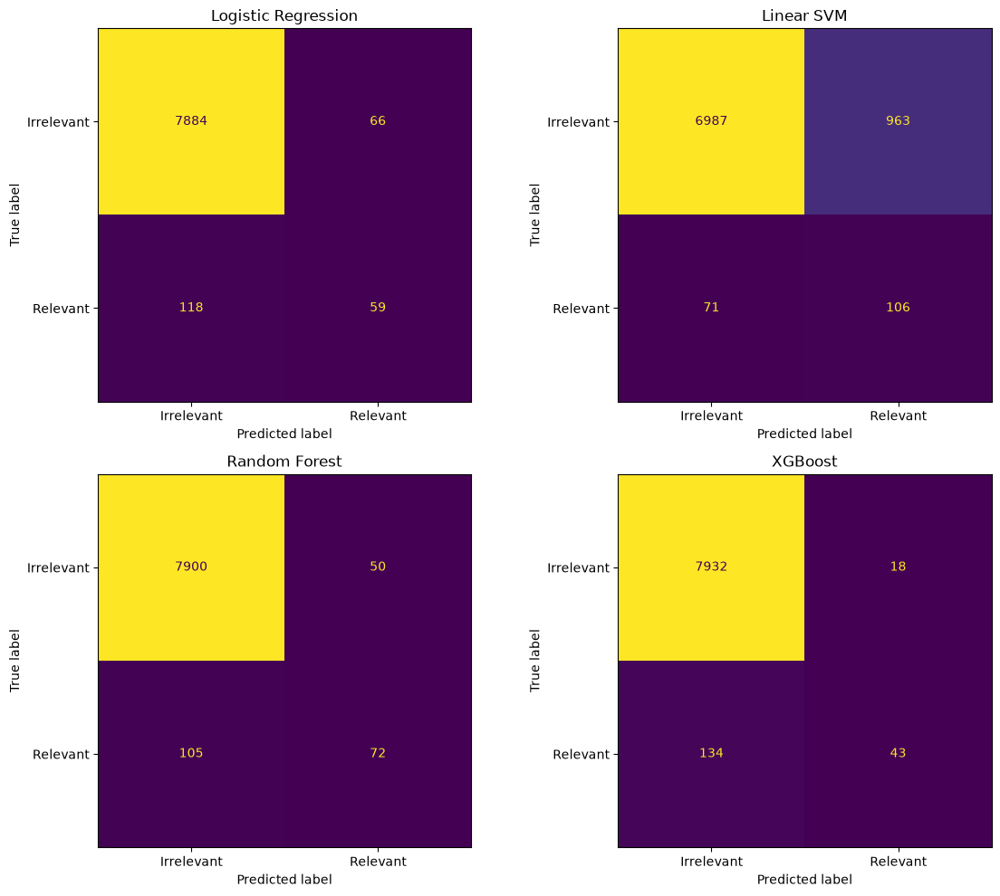

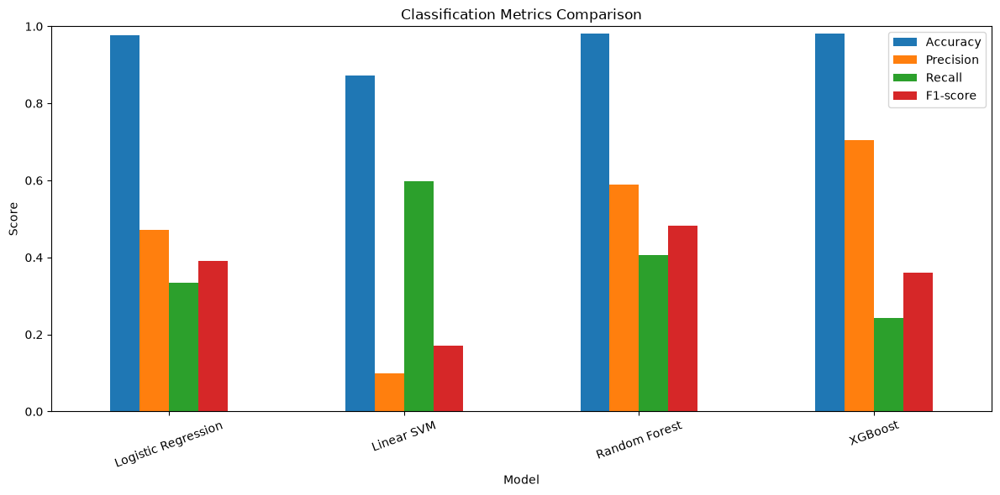

In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

# Prepare Logistic Regression predictions using saved parameters
X_val_scaled = (X_val - feature_mean_split) / np.where(
    feature_std_split == 0, 1, feature_std_split
)
X_val_bias = np.column_stack([
    np.ones(len(X_val_scaled)), X_val_scaled
])

logits = X_val_bias @ weights_split
logits = np.clip(logits, -500, 500)
lr_probabilities = 1 / (1 + np.exp(-logits))
lr_predictions = (lr_probabilities >= 0.5).astype(int)

# Predict with the three trained sklearn classifiers
models = {
    "Logistic Regression": lr_predictions,
    "Linear SVM": svm_model.predict(X_val),
    "Random Forest": rf_model.predict(X_val),
    "XGBoost": xgb_model.predict(X_val).astype(int)
}

# Calculate metrics
metric_rows = []

for name, predictions in models.items():
    cm = confusion_matrix(y_val, predictions, labels=[0, 1])

    metric_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

    print(f"\n{name}")
    print("Confusion matrix [[TN, FP], [FN, TP]]:")
    print(cm)

# Display metrics table
metrics_df = pd.DataFrame(metric_rows).set_index("Model")
display(metrics_df.round(4))

# Plot confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, predictions) in zip(axes.flat, models.items()):
    cm = confusion_matrix(y_val, predictions, labels=[0, 1])

    display_obj = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Irrelevant", "Relevant"]
    )
    display_obj.plot(ax=ax, values_format="d", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

# Plot classification metrics
metrics_df[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(12, 6), ylim=(0, 1), rot=20
)
plt.title("Classification Metrics Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="best")
plt.tight_layout()
plt.show()

In [59]:
print("Training qrels columns:", train_qrels_split.columns.tolist())
print("Validation qrels columns:", validation_qrels.columns.tolist())

print("\nTraining qrels sample:")
display(train_qrels_split.head())

print("\nValidation qrels sample:")
display(validation_qrels.head())

Training qrels columns: ['query-id', 'corpus-id', 'score']
Validation qrels columns: ['query-id', 'corpus-id', 'score']

Training qrels sample:


,query-id,corpus-id,score
0,0,31715818,1
1,2,13734012,1
2,4,22942787,1
3,6,2613775,1
4,9,44265107,1



Validation qrels sample:


,query-id,corpus-id,score
5,10,32587939,1
10,17,1606628,1
12,19,3202143,1
19,27,32390525,1
22,32,12428497,1


In [60]:
print("Training feature shape:", X_train_split.shape)
print("Training label shape:", y_train_split.shape)

print("\nTraining query count:",
      train_qrels_split["query-id"].nunique())

print("Validation query count:",
      validation_qrels["query-id"].nunique())

print("\nTraining query IDs overlap with validation:",
      len(
          set(train_qrels_split["query-id"].astype(str))
          & set(validation_qrels["query-id"].astype(str))
      ))

print("\nTraining label distribution:")
print(pd.Series(y_train_split).value_counts().sort_index())

Training feature shape: (32446, 5)
Training label shape: (32446,)

Training query count: 647
Validation query count: 162

Training query IDs overlap with validation: 0

Training label distribution:
0    31704
1      742
Name: count, dtype: int64


In [61]:
import inspect

for name in ["extract_features", "evaluate_classifier"]:
    print(f"\n--- {name} ---")
    print(inspect.getsource(globals()[name]))


--- extract_features ---
def extract_features(query, idx, bm25_score):
    query_tokens = tokenize(query)
    query_words = set(query_tokens)
    doc_words = set(tokenized_corpus[idx])

    overlap = len(query_words & doc_words)
    coverage = overlap / max(len(query_words), 1)
    doc_length = len(tokenized_corpus[idx])

    title_words = set(tokenize(corpus_df.iloc[idx]["title"]))
    title_overlap = len(query_words & title_words)

    return [
        bm25_score,
        overlap,
        coverage,
        doc_length,
        title_overlap
    ]


--- evaluate_classifier ---
def evaluate_classifier(model, k=10):
    reciprocal_ranks = []
    ndcg_scores = []

    for query_id, relevant_docs in validation_relevance.items():
        if not relevant_docs:
            continue

        query = query_text_by_id.get(str(query_id))
        if query is None:
            continue

        query_tokens = tokenize(query)
        bm25_scores = bm25.get_scores(query_tokens)
        candidate_ind

In [62]:
import json

with open("search_ranking.ipynb", "r", encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))
    if (
        "X_train_split" in source
        or "train_qrels_split" in source
        or "X_train" in source and "y_train" in source
    ):
        print(f"\n--- Cell {i + 1} ---")
        print(source[:5000])


--- Cell 18 ---

def extract_features(query, idx, bm25_score):
    query_tokens = tokenize(query)
    query_words = set(query_tokens)
    doc_words = set(tokenized_corpus[idx])

    overlap = len(query_words & doc_words)
    coverage = overlap / max(len(query_words), 1)
    doc_length = len(tokenized_corpus[idx])

    title_words = set(tokenize(corpus_df.iloc[idx]["title"]))
    title_overlap = len(query_words & title_words)

    return [
        bm25_score,
        overlap,
        coverage,
        doc_length,
        title_overlap
    ]

X_train_rows = []
y_train_rows = []

for query_id, relevant_ids in train_relevant.items():
    query = query_text_by_id.get(query_id)

    if query is None:
        continue

    scores = bm25.get_scores(tokenize(query))
    candidate_indices = np.argsort(scores)[::-1][:50]

    # Include known relevant documents even if BM25
    # did not retrieve them in the top 50.
    relevant_indices = [
        doc_index_by_id[doc_id]
        for doc_id in re

In [63]:
import numpy as np
import pandas as pd

X_grouped = []
y_grouped = []
query_groups = []

for query_id, relevant_ids in train_relevant_split.items():
    query_id = str(query_id)
    query = query_text_by_id.get(query_id)

    if query is None:
        continue

    scores = bm25.get_scores(tokenize(query))
    candidate_indices = set(
        np.argsort(scores)[::-1][:50].tolist()
    )

    relevant_indices = [
        doc_index_by_id[doc_id]
        for doc_id in relevant_ids
        if doc_id in doc_index_by_id
    ]
    candidate_indices.update(relevant_indices)

    for idx in candidate_indices:
        doc_id = str(corpus_df.iloc[idx]["_id"])

        X_grouped.append(
            extract_features(query, idx, float(scores[idx]))
        )
        y_grouped.append(int(doc_id in relevant_ids))
        query_groups.append(query_id)

X_grouped = np.asarray(X_grouped, dtype=float)
y_grouped = np.asarray(y_grouped, dtype=int)
query_groups = np.asarray(query_groups)

print("Feature matrix:", X_grouped.shape)
print("Labels:", y_grouped.shape)
print("Unique query groups:", len(np.unique(query_groups)))
print("Positive examples:", int(y_grouped.sum()))
print("Negative examples:", int((y_grouped == 0).sum()))

Feature matrix: (32446, 5)
Labels: (32446,)
Unique query groups: 647
Positive examples: 742
Negative examples: 31704


In [64]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, GridSearchCV

rf_base = RandomForestClassifier(
    random_state=42,
    class_weight="balanced",
    n_jobs=1
)

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 15],
    "min_samples_leaf": [1, 3]
}

group_cv = GroupKFold(n_splits=3)

rf_search = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    scoring="f1",
    cv=group_cv,
    n_jobs=1,
    verbose=1,
    refit=True
)

rf_search.fit(
    X_grouped,
    y_grouped,
    groups=query_groups
)

print("Best parameters:", rf_search.best_params_)
print("Best cross-validation F1:", round(rf_search.best_score_, 4))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}
Best cross-validation F1: 0.521


In [65]:
tuned_rf_model = rf_search.best_estimator_

tuned_rf_results = evaluate_classifier(tuned_rf_model, k=10)

print("Original Random Forest:", rf_results)
print("Tuned Random Forest:", tuned_rf_results)

Original Random Forest: {'MRR@10': 0.6523, 'NDCG@10': 0.6843}
Tuned Random Forest: {'MRR@10': 0.6649, 'NDCG@10': 0.6954}


In [66]:
import os
import json
import joblib

os.makedirs("saved_models", exist_ok=True)
os.makedirs("results", exist_ok=True)

joblib.dump(
    tuned_rf_model,
    "saved_models/tuned_random_forest.pkl"
)

all_results["Tuned Random Forest"] = {
    "MRR@10": tuned_rf_results["MRR@10"],
    "NDCG@10": tuned_rf_results["NDCG@10"]
}

with open("results/ranking_results.json", "w") as f:
    json.dump(all_results, f, indent=4)

print("Tuned Random Forest saved successfully!")
print("Ranking results updated!")

Tuned Random Forest saved successfully!
Ranking results updated!


In [67]:

import pandas as pd
import os

test_qrels_path = r"C:\Users\suhan\Downloads\scifact (1)\scifact\qrels\test.tsv"

test_qrels = pd.read_csv(test_qrels_path, sep="\t")

print("Test dataset loaded successfully!")
print("Shape:", test_qrels.shape)
print("\nFirst 5 rows:")
display(test_qrels.head())

print("\nColumns:", test_qrels.columns.tolist())
print("Unique test queries:", test_qrels["query-id"].nunique())


Test dataset loaded successfully!
Shape: (339, 3)

First 5 rows:


,query-id,corpus-id,score
0,1,31715818,1
1,3,14717500,1
2,5,13734012,1
3,13,1606628,1
4,36,5152028,1



Columns: ['query-id', 'corpus-id', 'score']
Unique test queries: 300


In [68]:

from collections import defaultdict

# Map each test query to its relevant document IDs
test_relevance = defaultdict(set)

for _, row in test_qrels.iterrows():
    if row["score"] > 0:
        test_relevance[str(row["query-id"])].add(str(row["corpus-id"]))

# Keep only queries that exist in the loaded query dataset
test_query_ids = [
    qid for qid in test_relevance
    if str(qid) in query_text_by_id
]

print("Test queries with relevant documents:", len(test_relevance))
print("Test queries available in queries_df:", len(test_query_ids))
print("Example query ID:", test_query_ids[0])
print("Example query:", query_text_by_id[test_query_ids[0]])


Test queries with relevant documents: 300
Test queries available in queries_df: 300
Example query ID: 1
Example query: 0-dimensional biomaterials show inductive properties.


In [69]:

import numpy as np
import pandas as pd
from collections import defaultdict
from IPython.display import display

# Store the final ranking metrics
test_results = {}

def evaluate_on_test(model=None, k=10):
    reciprocal_ranks = []
    ndcg_scores = []

    for query_id in test_query_ids:
        query = query_text_by_id[str(query_id)]
        relevant_docs = test_relevance[str(query_id)]

        # Retrieve candidates using BM25
        bm25_scores = bm25.get_scores(tokenize(query))
        candidate_indices = set(
            np.argsort(bm25_scores)[::-1][:50].tolist()
        )

        # Include known relevant documents for consistent reranking evaluation
        relevant_indices = [
            doc_index_by_id[doc_id]
            for doc_id in relevant_docs
            if doc_id in doc_index_by_id
        ]
        candidate_indices.update(relevant_indices)

        candidates = []
        for idx in candidate_indices:
            doc_id = str(corpus_df.iloc[idx]["_id"])
            score = float(bm25_scores[idx])

            if model is None:
                ranking_score = score
            else:
                features = np.asarray(
                    extract_features(query, idx, score),
                    dtype=float
                ).reshape(1, -1)

                if hasattr(model, "predict_proba"):
                    ranking_score = model.predict_proba(features)[0][1]
                elif hasattr(model, "decision_function"):
                    ranking_score = model.decision_function(features)[0]
                else:
                    ranking_score = model.predict(features)[0]

            candidates.append((doc_id, ranking_score))

        candidates.sort(key=lambda x: x[1], reverse=True)
        ranked_ids = [doc_id for doc_id, _ in candidates[:k]]

        # Reciprocal rank
        rr = 0.0
        for rank, doc_id in enumerate(ranked_ids, start=1):
            if doc_id in relevant_docs:
                rr = 1.0 / rank
                break
        reciprocal_ranks.append(rr)

        # Binary NDCG@k
        gains = [
            1 if doc_id in relevant_docs else 0
            for doc_id in ranked_ids
        ]
        dcg = sum(
            gain / np.log2(rank + 1)
            for rank, gain in enumerate(gains, start=1)
        )

        ideal_relevant = min(len(relevant_docs), k)
        idcg = sum(
            1 / np.log2(rank + 1)
            for rank in range(1, ideal_relevant + 1)
        )

        ndcg_scores.append(dcg / idcg if idcg else 0.0)

    return {
        "MRR@10": float(np.mean(reciprocal_ranks)),
        "NDCG@10": float(np.mean(ndcg_scores))
    }


# Evaluate both approaches on the same test queries
bm25_test_results = evaluate_on_test(model=None)
tuned_rf_test_results = evaluate_on_test(model=tuned_rf_model)

test_results["BM25"] = bm25_test_results
test_results["Tuned Random Forest"] = tuned_rf_test_results

comparison_df = pd.DataFrame(test_results).T
display(comparison_df.round(4))


,MRR@10,NDCG@10
BM25,0.6186,0.6519
Tuned Random Forest,0.6251,0.6609


In [70]:

import os
import json

os.makedirs("results", exist_ok=True)

results_path = "results/ranking_results.json"

if os.path.exists(results_path):
    with open(results_path, "r") as f:
        all_results = json.load(f)
else:
    all_results = {}

all_results["Final Test - BM25"] = bm25_test_results
all_results["Final Test - Tuned Random Forest"] = tuned_rf_test_results

with open(results_path, "w") as f:
    json.dump(all_results, f, indent=4)

print("Final test results saved successfully!")
print(json.dumps({
    "Final Test - BM25": bm25_test_results,
    "Final Test - Tuned Random Forest": tuned_rf_test_results
}, indent=4))


Final test results saved successfully!
{
    "Final Test - BM25": {
        "MRR@10": 0.6186150793650793,
        "NDCG@10": 0.6518925893260478
    },
    "Final Test - Tuned Random Forest": {
        "MRR@10": 0.6250555555555555,
        "NDCG@10": 0.6608695148528072
    }
}


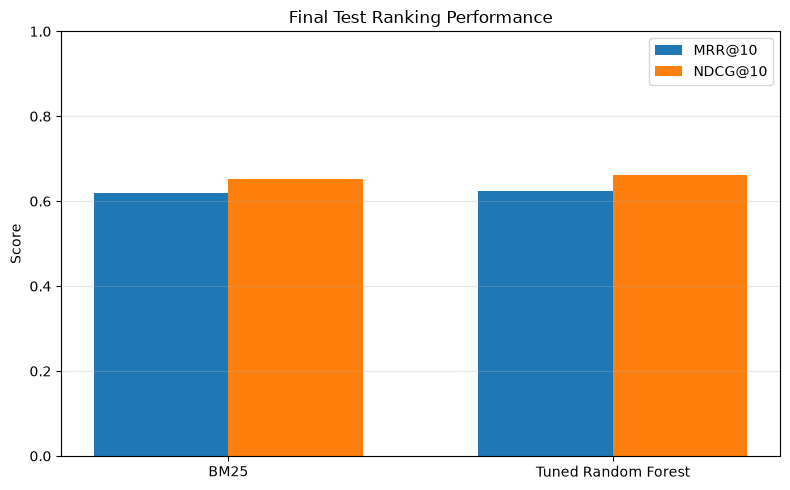

Graph saved to results/final_test_comparison.png


In [71]:

import matplotlib.pyplot as plt
import numpy as np

models = ["BM25", "Tuned Random Forest"]
mrr = [
    bm25_test_results["MRR@10"],
    tuned_rf_test_results["MRR@10"]
]
ndcg = [
    bm25_test_results["NDCG@10"],
    tuned_rf_test_results["NDCG@10"]
]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width/2, mrr, width, label="MRR@10")
ax.bar(x + width/2, ndcg, width, label="NDCG@10")

ax.set_ylabel("Score")
ax.set_title("Final Test Ranking Performance")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("results/final_test_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

print("Graph saved to results/final_test_comparison.png")


In [72]:

import numpy as np

def evaluate_end_to_end(model=None, k=10):
    reciprocal_ranks = []
    ndcg_scores = []

    for query_id in test_query_ids:
        query = query_text_by_id[str(query_id)]
        relevant_docs = test_relevance[str(query_id)]

        # Search only the documents actually retrieved by BM25
        bm25_scores = bm25.get_scores(tokenize(query))
        candidate_indices = np.argsort(bm25_scores)[::-1][:50]

        candidates = []

        for idx in candidate_indices:
            idx = int(idx)
            score = float(bm25_scores[idx])

            if model is None:
                ranking_score = score
            else:
                features = np.asarray(
                    extract_features(query, idx, score),
                    dtype=float
                ).reshape(1, -1)

                ranking_score = model.predict_proba(features)[0][1]

            doc_id = str(corpus_df.iloc[idx]["_id"])
            candidates.append((doc_id, ranking_score))

        candidates.sort(key=lambda x: x[1], reverse=True)
        ranked_ids = [doc_id for doc_id, _ in candidates[:k]]

        # MRR@10
        rr = 0.0
        for rank, doc_id in enumerate(ranked_ids, start=1):
            if doc_id in relevant_docs:
                rr = 1.0 / rank
                break
        reciprocal_ranks.append(rr)

        # NDCG@10
        gains = [
            1 if doc_id in relevant_docs else 0
            for doc_id in ranked_ids
        ]
        dcg = sum(
            gain / np.log2(rank + 1)
            for rank, gain in enumerate(gains, start=1)
        )

        ideal_count = min(len(relevant_docs), k)
        idcg = sum(
            1 / np.log2(rank + 1)
            for rank in range(1, ideal_count + 1)
        )
        ndcg_scores.append(dcg / idcg if idcg else 0.0)

    return {
        "MRR@10": float(np.mean(reciprocal_ranks)),
        "NDCG@10": float(np.mean(ndcg_scores))
    }


end_to_end_bm25 = evaluate_end_to_end()
end_to_end_rf = evaluate_end_to_end(tuned_rf_model)

print("End-to-end BM25:", end_to_end_bm25)
print("End-to-end Tuned Random Forest:", end_to_end_rf)


End-to-end BM25: {'MRR@10': 0.6186150793650793, 'NDCG@10': 0.6518925893260478}
End-to-end Tuned Random Forest: {'MRR@10': 0.5813690476190476, 'NDCG@10': 0.6088745081298328}


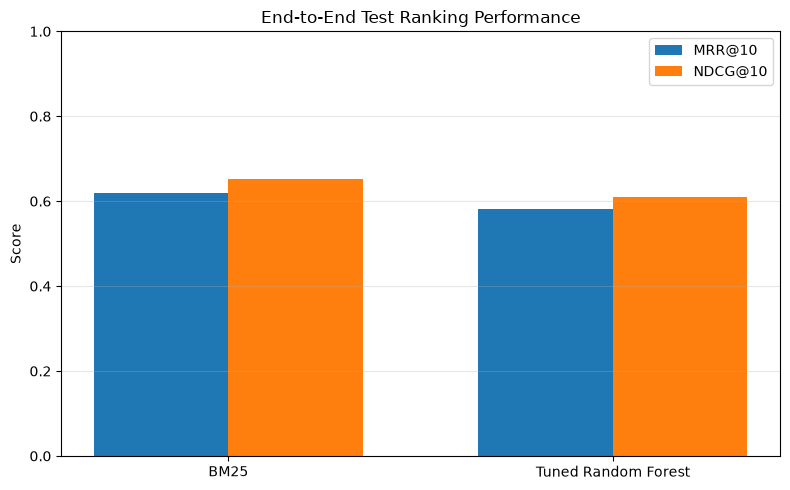

End-to-end results saved!
Graph saved to results/end_to_end_comparison.png


In [73]:

import json
import os
import matplotlib.pyplot as plt
import numpy as np

os.makedirs("results", exist_ok=True)

# Save the realistic evaluation separately
end_to_end_results = {
    "BM25": end_to_end_bm25,
    "Tuned Random Forest": end_to_end_rf
}

with open("results/end_to_end_results.json", "w") as f:
    json.dump(end_to_end_results, f, indent=4)

# Create an updated graph using end-to-end results
models = ["BM25", "Tuned Random Forest"]
mrr = [
    end_to_end_bm25["MRR@10"],
    end_to_end_rf["MRR@10"]
]
ndcg = [
    end_to_end_bm25["NDCG@10"],
    end_to_end_rf["NDCG@10"]
]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width / 2, mrr, width, label="MRR@10")
ax.bar(x + width / 2, ndcg, width, label="NDCG@10")

ax.set_ylabel("Score")
ax.set_title("End-to-End Test Ranking Performance")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "results/end_to_end_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("End-to-end results saved!")
print("Graph saved to results/end_to_end_comparison.png")


In [74]:

query = input("Enter a scientific search query: ")

results = search_documents(query, top_k=10)

if results is not None and not results.empty:
    display(results)
else:
    print("No results found. Try another query.")


,Rank,Document ID,Title,BM25 Score,Text Preview
0,1,10931595,"Geometry, epistasis, and developmental pattern...",9.1129,Developmental signaling networks are composed ...
1,2,10906636,The carboxyl terminus of human cytomegalovirus...,8.0543,US28 is one of four 7 transmembrane (7TM) chem...
2,3,13231899,In situ regulation of DC subsets and T cells m...,7.5915,Vaccines are largely ineffective for patients ...
3,4,12824568,From Cell Differentiation to Cell Collectives:...,7.4853,"The organization of cells, emerging from cell-..."
4,5,42240424,The effects of prion protein proteolysis and d...,7.3330,Native mammalian prions exist in self-propagat...
5,6,825728,Metastatic colonization requires the repressio...,6.9053,The epithelial-mesenchymal transition (EMT) is...
6,7,24998637,Interleukin 6 plays a key role in the developm...,6.8356,To investigate the direct role of interleukin ...
7,8,18953920,The Epithelial-Mesenchymal Transition Generate...,6.5679,The epithelial-mesenchymal transition (EMT) is...
8,9,19651306,Nanoenzymology of the 20S proteasome: proteaso...,6.5537,The proteasome is a major cytosolic proteolyti...
9,10,4465608,An atlas of active enhancers across human cell...,6.5000,Enhancers control the correct temporal and cel...


In [75]:

import os

for folder in ["saved_models", "results"]:
    print(f"\n--- {folder}/ ---")

    if os.path.exists(folder):
        for filename in sorted(os.listdir(folder)):
            path = os.path.join(folder, filename)
            size_kb = os.path.getsize(path) / 1024 if os.path.isfile(path) else 0
            print(f"{filename} ({size_kb:.1f} KB)" if os.path.isfile(path) else f"{filename}/")
    else:
        print("Folder not found")

print("\n--- Current project folder ---")
print(os.getcwd())



--- saved_models/ ---
search_ranking_models.pkl (46312.1 KB)
tuned_random_forest.pkl (32852.8 KB)
xgboost_model.json (395.0 KB)

--- results/ ---
end_to_end_comparison.png (65.9 KB)
end_to_end_results.json (0.2 KB)
final_test_comparison.png (64.3 KB)
ranking_results.json (0.7 KB)

--- Current project folder ---
c:\Users\suhan\Documents\search_ranking_project


In [76]:

from pathlib import Path

readme = r"""# Search Ranking Engine

## Overview
A scientific document search and ranking system built using the SciFact
dataset. The system retrieves relevant research documents for a user query
and ranks them using BM25 and machine-learning models.

## Dataset
- Dataset: SciFact (BEIR benchmark)
- Corpus: 5,183 scientific documents
- Queries: 1,109
- Test relevance judgments: 339
- Unique test queries: 300

The dataset contains scientific claims, research documents, and relevance
judgments used to evaluate information retrieval systems.

## Models
- BM25: lexical information-retrieval baseline
- Logistic Regression: binary relevance classification
- Linear SVM: binary relevance classification
- Random Forest: relevance classification and reranking
- XGBoost: relevance classification
- Tuned Random Forest: Random Forest selected through grouped
  cross-validation and hyperparameter tuning

## Features
The machine-learning models use five features:
1. BM25 retrieval score
2. Query-term overlap
3. Query-term coverage
4. Document length
5. Query-term overlap with the document title

## End-to-End Test Results

| Model | MRR@10 | NDCG@10 |
|---|---:|---:|
| BM25 | 0.6186 | 0.6519 |
| Tuned Random Forest | 0.5814 | 0.6089 |

BM25 achieved higher scores than the tuned Random Forest in the current
end-to-end evaluation. The Random Forest reranker therefore requires
further improvement before it can be considered better than the baseline.

Evaluation uses the top 50 documents retrieved by BM25, followed by
ranking the candidates. These results do not evaluate alternative
retrieval methods or documents outside that candidate set.

## Project Structure

search_ranking_project/
├── search_ranking.ipynb
├── saved_models/
│   ├── search_ranking_models.pkl
│   ├── tuned_random_forest.pkl
│   └── xgboost_model.json
└── results/
    ├── ranking_results.json
    ├── end_to_end_results.json
    ├── final_test_comparison.png
    └── end_to_end_comparison.png

## How to Run
1. Open this project folder in VS Code.
2. Open the Jupyter notebook.
3. Select the Python environment containing the required libraries.
4. Run the notebook cells in order to load the dataset, build the index,
   train or load models, evaluate ranking performance, and run searches.
5. Use the interactive search cell to enter a scientific query and view
   the ranked documents.

The dataset path in the notebook may need to be updated to match your
computer.

## Evaluation Metrics
- MRR@10: measures how highly the first relevant result appears.
- NDCG@10: measures the quality of the ordering of relevant results
  within the top 10.

## Future Improvements
- Improve relevance ranking using learning-to-rank methods.
- Investigate queries for which BM25 retrieves weak candidates.
- Add a user interface for search and document inspection.
- Evaluate additional retrieval methods and compare their performance.
"""

Path("README.md").write_text(readme, encoding="utf-8")

print("README.md created at:", Path("README.md").resolve())
print("File size:", Path("README.md").stat().st_size, "bytes")


README.md created at: C:\Users\suhan\Documents\search_ranking_project\README.md
File size: 3046 bytes


In [1]:

import joblib
import os

model_path = "saved_models/search_ranking_models.pkl"
tuned_path = "saved_models/tuned_random_forest.pkl"

print("Original model file exists:", os.path.exists(model_path))
print("Tuned Random Forest exists:", os.path.exists(tuned_path))

if os.path.exists(model_path):
    saved_objects = joblib.load(model_path)
    print("\nSaved objects:", list(saved_objects.keys()))

if os.path.exists(tuned_path):
    tuned_rf_model = joblib.load(tuned_path)
    print("Tuned Random Forest loaded:", type(tuned_rf_model).__name__)

print("\nCorpus shape:", corpus_df.shape)
print("Corpus columns:", corpus_df.columns.tolist())


Original model file exists: True
Tuned Random Forest exists: True

Saved objects: ['bm25', 'corpus_df', 'tokenized_corpus', 'svm_model', 'rf_model', 'logistic_weights', 'feature_mean', 'feature_std']
Tuned Random Forest loaded: RandomForestClassifier


NameError: name 'corpus_df' is not defined